# Module 2 — Backtesting de Kupiec (hors échantillon, XAU/USD)

Objectif : répondre proprement à la question laissée ouverte à la fin du
notebook 4 — est-ce que chacune des 3 méthodes de VaR tient ses promesses
sur des données qu'elle n'a jamais vues au moment de la calibration ?
Contrairement au comptage in-sample du notebook 4 (quasi tautologique),
ce notebook simule un vrai usage opérationnel : chaque jour, on calibre
la VaR uniquement sur le passé, puis on vérifie si le rendement du
lendemain (inconnu au moment de la calibration) la dépasse.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (12, 4.5)

df = pd.read_csv("../data/processed/xau_1d_processed.csv", index_col=0, parse_dates=True)
returns = df["log_return"]
r = returns.to_numpy()
dates = returns.index
n = len(r)

## 1. Méthodologie : fenêtre glissante, sans fuite d'information

- **Fenêtre de calibration** : 500 jours ouvrés (~2 ans). Pour chaque
  jour de test `t`, on calibre les 3 méthodes exclusivement sur les 500
  jours qui précèdent `t` (`[t-500, t[`), jamais sur `t` lui-même ni sur
  le futur.
- **Test** : on compare le rendement *réellement observé* au jour `t` au
  seuil de VaR calculé à partir du passé. Un "breach" (dépassement) est
  enregistré si la perte réelle dépasse la VaR.
- **Niveau de confiance** : 99% (standard Basel pour le risque de
  marché) — sur `n` jours de test, on *attend* en moyenne `1% × n`
  dépassements si le modèle est bien calibré.
- Les 4 rendements neutralisés en section 5 du notebook 1 (jours à cheval
  sur le trou de données) sont exclus du test (on ne peut pas évaluer un
  modèle sur une observation qu'on a nous-mêmes jugée invalide), mais
  restent utilisables dans les fenêtres de calibration qui les précèdent
  une fois qu'ils ne sont plus le jour testé.

In [2]:
WINDOW = 500
ALPHA = 0.01
N_MC = 5_000
rng = np.random.default_rng(7)

records = []
for t in range(WINDOW, n):
    window = r[t - WINDOW:t]
    window = window[~np.isnan(window)]
    actual = r[t]
    if np.isnan(actual):
        continue  # jour neutralisé (cross-gap), non testable

    var_h = -np.percentile(window, ALPHA * 100)

    mean_w, std_w = window.mean(), window.std()
    z = stats.norm.ppf(ALPHA)
    var_p = -(mean_w + z * std_w)

    sim = rng.normal(mean_w, std_w, N_MC)
    var_mc = -np.percentile(sim, ALPHA * 100)

    records.append((dates[t], actual, var_h, var_p, var_mc))

bt = pd.DataFrame(records, columns=["date", "actual", "var_h", "var_p", "var_mc"]).set_index("date")
bt["breach_h"] = bt["actual"] < -bt["var_h"]
bt["breach_p"] = bt["actual"] < -bt["var_p"]
bt["breach_mc"] = bt["actual"] < -bt["var_mc"]

print(f"Période de test : {bt.index.min().date()} → {bt.index.max().date()} ({len(bt)} jours)")
print(f"Dépassements attendus sous bonne calibration : {ALPHA:.0%} × {len(bt)} ≈ {ALPHA*len(bt):.1f} jours")

Période de test : 2006-06-07 → 2026-01-30 (5028 jours)
Dépassements attendus sous bonne calibration : 1% × 5028 ≈ 50.3 jours


## 2. Le test de Kupiec (Proportion of Failures)

Le test de Kupiec compare le taux de dépassement *observé* au taux
*attendu* (1%), via un ratio de vraisemblance :

`LR_POF = -2·ln[ (1-p)^(N-x)·p^x / (1-x̂)^(N-x)·x̂^x ]`

où `p` = 1% (attendu), `x` = nombre de dépassements observés, `N` =
nombre de jours testés, `x̂ = x/N` (taux observé). Sous l'hypothèse que
le modèle est bien calibré, `LR_POF` suit une loi du χ² à 1 degré de
liberté — on rejette la calibration si `LR_POF` dépasse le seuil critique
(3,84 à 95% de confiance), ce qui revient à dire que le taux observé
s'écarte trop du taux attendu pour être dû au hasard.

In [3]:
def kupiec_pof(x: int, N: int, p: float) -> dict:
    if x == 0:
        lr = -2 * N * np.log(1 - p)
    else:
        xhat = x / N
        lr = -2 * ((N - x) * np.log(1 - p) + x * np.log(p) - (N - x) * np.log(1 - xhat) - x * np.log(xhat))
    pval = 1 - stats.chi2.cdf(lr, df=1)
    return {"x": x, "N": N, "rate": x / N, "LR_POF": lr, "p_value": pval, "rejete_5pct": pval < 0.05}


kupiec_results = {}
for label, col in [("Historique", "breach_h"), ("Paramétrique", "breach_p"), ("Monte Carlo", "breach_mc")]:
    kupiec_results[label] = kupiec_pof(int(bt[col].sum()), len(bt), ALPHA)

kupiec_table = pd.DataFrame(kupiec_results).T
kupiec_table

,x,N,rate,LR_POF,p_value,rejete_5pct
Historique,62,5028,0.012331,2.568964,0.108979,False
Paramétrique,93,5028,0.018496,29.316219,0.0,True
Monte Carlo,96,5028,0.019093,33.155462,0.0,True


**Interprétation — le résultat central de tout le pipeline construit
depuis le notebook 1** :

- **Historique** : 62 dépassements sur 5028 jours (1,23%, contre 1,00%
  attendu). `LR_POF = 2,57`, p-value = **0,109** → on ne rejette **pas**
  la calibration à 95% de confiance. Le léger excès de dépassements n'est
  pas statistiquement significatif — la méthode historique est
  validée par ce test.
- **Paramétrique** : 93 dépassements (1,85%, soit près du double de
  l'attendu). `LR_POF = 29,3`, p-value **≈ 0,0000** → calibration
  **rejetée** sans ambiguïté.
- **Monte Carlo** : 96 dépassements (1,91%). `LR_POF = 33,2`, p-value
  **≈ 0,0000** → également **rejetée**.

C'est la confirmation empirique, hors échantillon et avec un vrai test
statistique (pas un comptage approximatif), de ce que toute la chaîne de
notebooks précédente laissait prévoir : les méthodes qui supposent la
normalité des rendements (paramétrique et Monte Carlo, puisque le
simulateur du notebook 3 tire des `Z` normaux) **sous-estiment
systématiquement et significativement le risque réel de l'or**, au point
que leur calibration est statistiquement rejetée sur 20 ans de données
hors échantillon. La méthode historique, qui ne fait aucune hypothèse de
distribution, résiste au test. C'est un résultat qu'on peut maintenant
affirmer avec un test formel derrière, pas juste une intuition.

## 3. Visualisation — seuils de VaR vs rendements réels

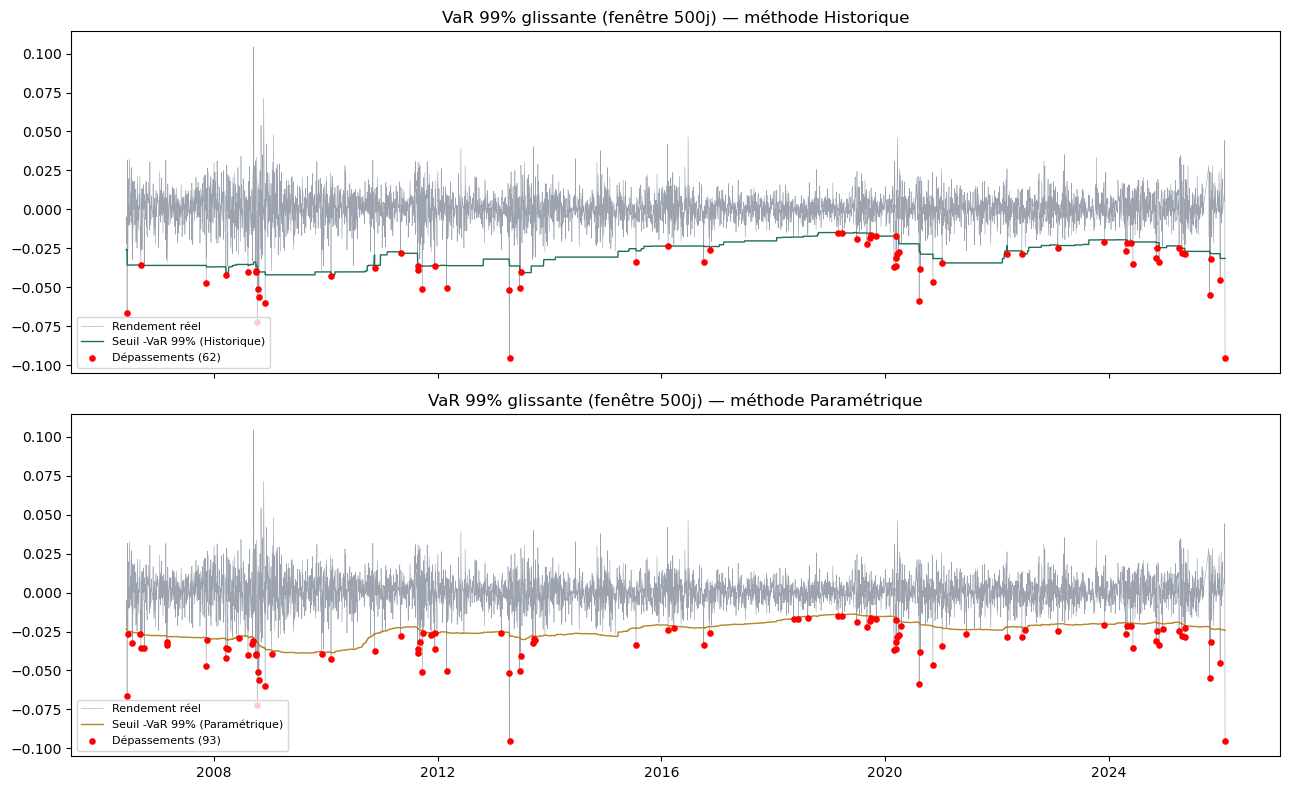

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

for ax, (label, var_col, breach_col, color) in zip(
    axes,
    [("Historique", "var_h", "breach_h", "#1f6f54"), ("Paramétrique", "var_p", "breach_p", "#b5862c")],
):
    ax.plot(bt.index, bt["actual"], color="#9ca3af", linewidth=0.4, label="Rendement réel")
    ax.plot(bt.index, -bt[var_col], color=color, linewidth=1, label=f"Seuil -VaR 99% ({label})")
    breaches = bt[bt[breach_col]]
    ax.scatter(breaches.index, breaches["actual"], color="red", s=14, zorder=5, label=f"Dépassements ({len(breaches)})")
    ax.set_title(f"VaR 99% glissante (fenêtre 500j) — méthode {label}")
    ax.legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()

**Interprétation** — les deux graphiques partagent la même échelle et la
même période de test, ce qui rend la comparaison directe : le seuil de
VaR paramétrique (en orange) est visiblement plus proche de zéro — donc
plus permissif, plus souvent franchi — que le seuil historique (en vert)
pendant les mêmes périodes de stress. On voit aussi, à l'œil, que les
points rouges (dépassements) ne sont pas répartis uniformément dans le
temps : ils se concentrent nettement autour de certaines fenêtres (fin
2008, 2013, et la fin de série 2025-2026) plutôt que d'être dispersés au
hasard sur 20 ans — on y revient formellement en section 5.

## 4. Zones Bâloises (feu tricolore, fenêtre glissante de 250 jours)

En pratique réglementaire, Bâle ne regarde pas tout l'historique de
backtesting : il classe la banque selon le nombre de dépassements
observés sur les **250 derniers jours de trading**, dans l'une de 3
zones, qui déterminent un multiplicateur de capital réglementaire :

| Zone | Dépassements (sur 250j, VaR 99%) | Conséquence |
|---|---|---|
| 🟢 Verte | 0 à 4 | Modèle jugé fiable, multiplicateur minimal |
| 🟡 Jaune | 5 à 9 | Zone d'alerte, multiplicateur croissant |
| 🔴 Rouge | 10 et plus | Modèle jugé défaillant, multiplicateur maximal |

In [5]:
def basel_zone(x_250: int) -> str:
    if x_250 <= 4:
        return "VERTE"
    elif x_250 <= 9:
        return "JAUNE"
    return "ROUGE"


zone_rows = []
for label, col in [("Historique", "breach_h"), ("Paramétrique", "breach_p"), ("Monte Carlo", "breach_mc")]:
    x250 = int(bt[col].tail(250).sum())
    zone_rows.append({"méthode": label, "dépassements_250j": x250, "zone": basel_zone(x250)})

pd.DataFrame(zone_rows)

,méthode,dépassements_250j,zone
0,Historique,7,JAUNE
1,Paramétrique,8,JAUNE
2,Monte Carlo,8,JAUNE


**Interprétation** — sur les 250 derniers jours de test (qui couvrent la
période particulièrement mouvementée de fin 2025 / début 2026), les 3
méthodes tombent en zone **JAUNE** (historique : 7 dépassements,
paramétrique et Monte Carlo : 8 chacune) — aucune en zone rouge, mais
aucune non plus en zone verte.

Ce résultat semble moins tranché que celui de la section 2, et c'est
normal : **250 observations, c'est un échantillon statistiquement
faible** comparé aux 5028 jours du test complet. Avec si peu
d'observations, la différence entre 7 et 8 dépassements n'est pas
significative — le test de Kupiec sur l'échantillon complet (section 2)
a beaucoup plus de puissance statistique pour distinguer les méthodes.
C'est d'ailleurs une limite connue et documentée du cadre réglementaire
bâlois lui-même : la fenêtre de 250 jours est un compromis pratique
(représente environ 1 an de trading, se recalcule en continu), pas le
test statistiquement le plus puissant disponible. Les deux résultats ne
se contredisent pas : ils répondent à deux questions différentes ("la
méthode est-elle fiable sur le long terme ?" vs "la méthode a-t-elle
dérapé récemment ?").

## 5. Limite du test de Kupiec : il ne teste pas l'indépendance

Le test de Kupiec vérifie uniquement la *fréquence* des dépassements —
pas s'ils sont indépendants dans le temps. Un modèle pourrait avoir
exactement le bon nombre de dépassements sur l'année, mais tous
concentrés sur la même semaine de crise : Kupiec seul ne verrait aucun
problème, alors qu'un risk manager, lui, devrait s'inquiéter. Le test de
**Christoffersen** complète Kupiec en testant spécifiquement
l'indépendance des dépassements (est-ce qu'un dépassement aujourd'hui
augmente la probabilité d'un dépassement demain ?).

In [6]:
def christoffersen_independence(breach: pd.Series) -> dict:
    b = breach.astype(int).to_numpy()
    n00 = n01 = n10 = n11 = 0
    for i in range(1, len(b)):
        prev, cur = b[i - 1], b[i]
        if prev == 0 and cur == 0: n00 += 1
        elif prev == 0 and cur == 1: n01 += 1
        elif prev == 1 and cur == 0: n10 += 1
        elif prev == 1 and cur == 1: n11 += 1
    n0, n1 = n00 + n01, n10 + n11
    pi01 = n01 / n0 if n0 else 0
    pi11 = n11 / n1 if n1 else 0
    pi = (n01 + n11) / (n0 + n1)

    def _ll(p, k1, k0):
        t = 0.0
        if k0 > 0 and p < 1: t += k0 * np.log(1 - p)
        if k1 > 0 and p > 0: t += k1 * np.log(p)
        return t

    ll_restricted = _ll(pi, n01 + n11, n00 + n10)
    ll_unrestricted = _ll(pi01, n01, n00) + _ll(pi11, n11, n10)
    lr_ind = -2 * (ll_restricted - ll_unrestricted)
    pval = 1 - stats.chi2.cdf(lr_ind, df=1)
    return {"pi01_prob_breach_apres_calme": pi01, "pi11_prob_breach_apres_breach": pi11, "LR_independence": lr_ind, "p_value": pval}


indep_rows = []
cc_rows = []
for label, col in [("Historique", "breach_h"), ("Paramétrique", "breach_p"), ("Monte Carlo", "breach_mc")]:
    ind = christoffersen_independence(bt[col])
    indep_rows.append({"méthode": label, **ind})
    lr_cc = kupiec_results[label]["LR_POF"] + ind["LR_independence"]
    pval_cc = 1 - stats.chi2.cdf(lr_cc, df=2)
    cc_rows.append({"méthode": label, "LR_conditional_coverage": lr_cc, "p_value": pval_cc, "rejete_5pct": pval_cc < 0.05})

indep_table = pd.DataFrame(indep_rows).set_index("méthode")
cc_table = pd.DataFrame(cc_rows).set_index("méthode")
print("Test d'indépendance de Christoffersen :")
display(indep_table)
print("\nTest combiné (Kupiec + Christoffersen = couverture conditionnelle) :")
display(cc_table)

Test d'indépendance de Christoffersen :


,pi01_prob_breach_apres_calme,pi11_prob_breach_apres_breach,LR_independence,p_value
méthode,,,,
Historique,0.011881,0.049180,3.973230,0.046229
Paramétrique,0.017832,0.054348,4.425092,0.035414
Monte Carlo,0.018451,0.052632,3.987591,0.045837



Test combiné (Kupiec + Christoffersen = couverture conditionnelle) :


,LR_conditional_coverage,p_value,rejete_5pct
méthode,,,
Historique,6.542194,3.796475e-02,True
Paramétrique,33.741311,4.711590e-08,True
Monte Carlo,37.143052,8.599806e-09,True


**Interprétation** — pour les 3 méthodes, `π11` (probabilité d'un
dépassement sachant qu'il y en a eu un la veille) est nettement plus
élevée que `π01` (probabilité d'un dépassement sachant un jour calme la
veille) : environ ×4 pour la méthode historique (4,9% contre 1,2%), un
ratio similaire pour les deux autres. Les dépassements ne sont donc
**pas indépendants dans le temps** — ils ont tendance à s'enchaîner. Ce
n'est pas une surprise : c'est la même propriété de clustering de
volatilité identifiée dès le notebook 1 (les périodes agitées restent
agitées plusieurs jours de suite) qui se traduit ici directement par un
clustering des dépassements de VaR.

Conséquence importante et nuancée pour le rapport : **même la méthode
historique, qui passait le test de Kupiec seul (section 2), échoue au
test combiné de couverture conditionnelle** (p-value = 0,038, sous le
seuil de 5%) — alors que paramétrique et Monte Carlo échouent ce même
test de façon encore plus massive (p ≈ 0,0000). Autrement dit : la
méthode historique reste clairement la meilleure des 3 sur ces données,
mais elle n'est pas parfaite pour autant — aucune des 3 méthodes ne
capture complètement le fait que le risque de l'or n'est pas constant
dans le temps mais évolue par régimes. C'est une limite honnête à
documenter plutôt qu'à cacher, et ça ouvre une piste claire pour une
évolution future du module (hors scope de cette version) : un modèle à
volatilité conditionnelle (type GARCH), qui recalibre σ dynamiquement
jour après jour plutôt que sur une fenêtre fixe, capturerait
naturellement ce clustering.

## 6. Sauvegarde

In [7]:
bt.to_csv("../data/processed/kupiec_backtest_series.csv")
kupiec_table.to_csv("../data/processed/kupiec_results.csv")
print("Sauvegardés : kupiec_backtest_series.csv, kupiec_results.csv")

Sauvegardés : kupiec_backtest_series.csv, kupiec_results.csv


## 7. Résumé & où en est le module

- Backtesting hors échantillon (fenêtre glissante 500j, 5028 jours
  testés, 2006-2026) implémenté et exécuté pour les 3 méthodes de VaR.
- **Résultat central** : la méthode historique n'est pas rejetée par le
  test de Kupiec (p=0,109) ; paramétrique et Monte Carlo le sont
  nettement (p≈0,0000) — confirmation statistique, hors échantillon, que
  l'hypothèse de normalité sous-estime le risque réel de l'or.
- Zones Bâloises (250 derniers jours) : les 3 méthodes en zone JAUNE —
  résultat moins tranché qu'avec le test complet, pour une raison
  méthodologique claire (puissance statistique limitée sur 250
  observations), explicitement documentée.
- Test d'indépendance de Christoffersen : dépassements non indépendants
  pour les 3 méthodes (clustering, cohérent avec la volatilité en
  grappes déjà identifiée) — même la méthode historique échoue le test
  combiné de couverture conditionnelle, limite honnête à assumer plutôt
  qu'à masquer. Piste d'évolution identifiée (GARCH) mais hors scope
  actuel.

**Ce qui est maintenant disponible** : un pipeline complet et validé
empiriquement — prétraitement → calibration GBM → simulation Monte Carlo
→ VaR (3 méthodes) + ES → backtesting Kupiec — avec un choix de méthode
justifié par des tests statistiques, pas par préférence arbitraire.

**Prochaine étape naturelle** : le mécanisme de stratégies recommandées
aux clients (risk-budgeting à partir de la VaR/ES validées), puis la VaR
stressée (recalibration sur la fenêtre de crise identifiée) — les deux
volets fonctionnels restants du périmètre du module.